# Задача 2. Validate BST

**Объяснение решения**

Использую то же правило, что и в первой задаче: в левом поддереве
значения меньше текущего, в правом - больше или равны.
Повторы допускаются справа.

Для каждого узла нужно учитывать ограничения от всех его предков.
Например, если узел находится в левом поддереве `8`, его значение должно
быть меньше `8`, даже если между ними есть другие узлы.

Функция `is_valid_bst` запускает рекурсивную функцию `check`.
В неё передаются текущий узел и две границы: `lower` и `upper`.
Значение узла должно быть **не меньше нижней границы и меньше верхней**.
`None` означает, что соответствующей границы нет. Для корня обе границы
отсутствуют.

Базовый случай - `node is None`: пустое поддерево считается корректным,
поэтому возвращаем `True`. Если значение нарушает хотя бы одну границу,
сразу возвращаем `False`.

Для левого поддерева сохраняем нижнюю границу и делаем значение текущего
узла новой верхней границей. Для правого - сохраняем верхнюю границу,
а значение узла становится новой нижней границей. Затем рекурсивно
проверяем оба поддерева. Результат - `True`, только если обе проверки
вернули `True`.

Границы сохраняют ограничения всех предков. Если текущий узел проходит
проверку, а оба поддерева корректны в своих границах, всё поддерево
тоже является BST. Для пустого поддерева это верно сразу, поэтому
по индукции проверка корректна для всего дерева.

**Решение**

In [1]:
from __future__ import annotations

from dataclasses import dataclass


@dataclass
class Node:
    value: int
    left: Node | None = None
    right: Node | None = None


def is_valid_bst(root: Node | None) -> bool:
    """BST: слева значения < value, справа значения >= value."""

    def check(node: Node | None, lower: int | None, upper: int | None) -> bool:
        if node is None:
            return True

        if lower is not None and node.value < lower:
            return False
        if upper is not None and node.value >= upper:
            return False

        return (
            check(node.left, lower, node.value)
            and check(node.right, node.value, upper)
        )

    return check(root, None, None)

**Пример**

Возьмём дерево из первой задачи. Все его узлы удовлетворяют свойству BST,
поэтому результат проверки - `True`.

Во втором дереве заменим `7` на `9`. Узел `9` больше своего родителя `6`,
но находится в левом поддереве `8`. Значит, всё дерево некорректно,
и результат должен быть `False`.

Деревья создаю вручную через `Node`, чтобы можно было задать и неправильную
структуру. Для рисунков беру ячейку из первой задачи, чтобы не рисовать
руками) Метки `L` и `R` показывают направление связи, красным выделен узел
с нарушением.

In [2]:
from html import escape
from IPython.display import HTML, Markdown, SVG, display


def tree_svg(root, title="Бинарное дерево", highlight=None):
    """SVG-схема небольшого дерева; расположение узлов задаёт inorder."""
    if root is None:
        return (
            '<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 720 140">'
            '<rect width="720" height="140" rx="16" fill="#f8fafc"/>'
            f'<text x="24" y="36" font-family="sans-serif" font-size="20" '
            f'fill="#0f172a">{escape(title)}</text>'
            '<text x="360" y="95" text-anchor="middle" font-family="sans-serif" '
            'font-size="18" fill="#475569">Пустое дерево: root = None</text></svg>'
        )

    ordered = []

    def collect(node, depth):
        if node is None:
            return
        collect(node.left, depth + 1)
        ordered.append((node, depth))
        collect(node.right, depth + 1)

    collect(root, 0)

    width, margin, level_gap, radius = 720, 48, 88, 22
    height = 135 + level_gap * max(depth for _, depth in ordered)
    positions = {}
    for index, (node, depth) in enumerate(ordered):
        x = width / 2 if len(ordered) == 1 else (
            margin + index * (width - 2 * margin) / (len(ordered) - 1)
        )
        positions[id(node)] = (x, 85 + level_gap * depth)

    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" '
        f'width="{width}" role="img" aria-label="{escape(title, quote=True)}">',
        f'<rect width="{width}" height="{height}" rx="16" fill="#f8fafc"/>',
        f'<text x="24" y="34" font-family="sans-serif" font-size="20" '
        f'font-weight="600" fill="#0f172a">{escape(title)}</text>',
    ]
    for node, _ in ordered:
        x1, y1 = positions[id(node)]
        for child, label in ((node.left, "L"), (node.right, "R")):
            if child is None:
                continue
            x2, y2 = positions[id(child)]
            parts.append(
                f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" '
                'stroke="#94a3b8" stroke-width="2.5"/>'
            )
            parts.append(
                f'<text x="{(x1 + x2) / 2}" y="{(y1 + y2) / 2 - 7}" '
                'text-anchor="middle" font-family="sans-serif" font-size="13" '
                'fill="#475569" stroke="#f8fafc" stroke-width="4" '
                f'paint-order="stroke">{label}</text>'
            )
    for node, _ in ordered:
        x, y = positions[id(node)]
        fill = "#fee2e2" if node is highlight else "#e0e7ff"
        stroke = "#dc2626" if node is highlight else "#4f46e5"
        parts.extend([
            f'<circle cx="{x}" cy="{y}" r="{radius}" fill="{fill}" '
            f'stroke="{stroke}" stroke-width="2"/>',
            f'<text x="{x}" y="{y + 6}" text-anchor="middle" '
            'font-family="sans-serif" font-size="18" font-weight="600" '
            f'fill="#312e81">{node.value}</text>',
        ])
    parts.append('</svg>')
    return ''.join(parts)

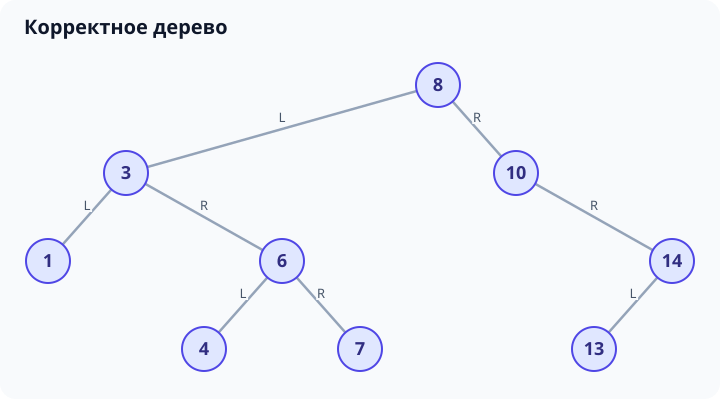

Результат проверки: **True**

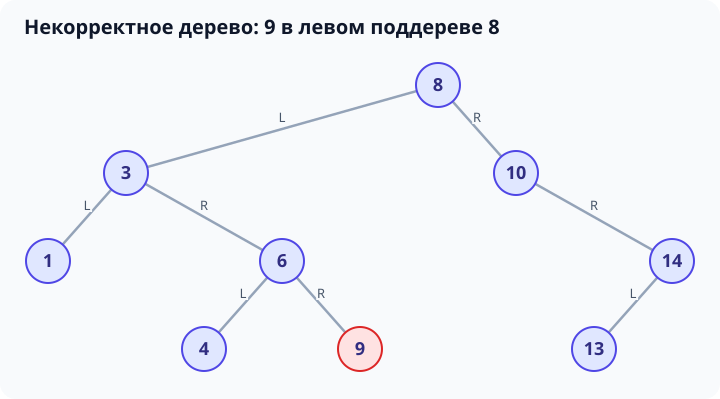

Результат проверки: **False**

In [3]:
valid_tree = Node(
    8,
    left=Node(3, left=Node(1), right=Node(6, left=Node(4), right=Node(7))),
    right=Node(10, right=Node(14, left=Node(13))),
)

invalid_node = Node(9)
invalid_tree = Node(
    8,
    left=Node(3, left=Node(1), right=Node(6, left=Node(4), right=invalid_node)),
    right=Node(10, right=Node(14, left=Node(13))),
)

display(SVG(tree_svg(valid_tree, "Корректное дерево")))
display(Markdown(f"Результат проверки: **{is_valid_bst(valid_tree)}**"))

display(SVG(tree_svg(invalid_tree, "Некорректное дерево: 9 в левом поддереве 8", invalid_node)))
display(Markdown(f"Результат проверки: **{is_valid_bst(invalid_tree)}**"))

**Пошаговая работа `is_valid_bst`.** Рассмотрим второе дерево.
Начинаем с `check(8, None, None)`. Сначала проверяем текущий узел,
затем рекурсивно левое поддерево и после него правое.

В таблице показаны границы и результат проверки значения текущего узла.
Вызовы для `None` сразу возвращают `True` и в таблицу не включены.

| Шаг | Узел | Нижняя граница | Верхняя граница | Проверка значения |
|---|---:|---|---|---|
| 1 | 8 | Нет | Нет | Ограничений нет |
| 2 | 3 | Нет | 8 | `3 < 8` - верно |
| 3 | 1 | Нет | 3 | `1 < 3` - верно |
| 4 | 6 | 3 | 8 | `3 <= 6 < 8` - верно |
| 5 | 4 | 3 | 6 | `3 <= 4 < 6` - верно |
| 6 | 9 | 6 | 8 | `6 <= 9 < 8` - неверно |

Для узла `9` срабатывает условие `node.value >= upper`, поэтому этот
вызов возвращает `False`. Результат передаётся вверх по цепочке
`9 → 6 → 3 → 8`.

Из-за `and` правое поддерево корня уже не проверяется: найденного нарушения
достаточно, чтобы вернуть `False` для всего дерева. В первом дереве на
этом месте находится `7`, который проходит проверку `6 <= 7 < 8`.
Остальные узлы первого дерева тоже проходят свои проверки, итог - `True`.

**Сложность**

Пусть `n` - число узлов, а `h` - высота дерева (глубина).
Сравнение целых чисел считаем операцией `O(1)`.

| Операция | Время | Память |
|---|---|---|
| Проверка непустого дерева | `O(n)` в худшем случае | `O(h)` для стека вызовов |
| Проверка пустого дерева | `O(1)` | `O(1)` |

Каждый узел посещается не больше одного раза. Для него выполняются
две проверки границ и рекурсивные вызовы для детей. Если нарушение найдено
раньше, оставшаяся часть дерева не обходится, но в худшем случае нужно
проверить все `n` узлов.

Максимальное число одновременно активных вызовов пропорционально высоте
дерева. При сбалансированной форме память составляет `O(log n)`,
у дерева-цепочки - `O(n)`. Дополнительный список узлов не создаётся,
возвращается только `True` или `False`. Само входное дерево в оценку
дополнительной памяти не включаем.

Python ограничивает глубину рекурсии. Для теста с цепочками из 2500 узлов
лимит временно увеличивается до 6000 или сохраняется более высокий
исходный лимит. После теста исходное значение восстанавливается.

**Тесты**

In [4]:
import sys
import unittest
from copy import deepcopy
from itertools import product


class TestValidateBST(unittest.TestCase):
    def test_empty(self):
        self.assertIs(is_valid_bst(None), True)

    def test_single(self):
        for value in [0, -7, 42]:
            with self.subTest(value=value):
                self.assertIs(is_valid_bst(Node(value)), True)

    def test_balanced(self):
        root = Node(
            4,
            Node(2, Node(1), Node(3)),
            Node(6, Node(5), Node(7)),
        )
        self.assertIs(is_valid_bst(root), True)

    def test_unbalanced(self):
        root = Node(
            8,
            left=Node(3, right=Node(6, left=Node(4))),
            right=Node(10, right=Node(14, left=Node(13))),
        )
        self.assertIs(is_valid_bst(root), True)

    def test_left_child_violation(self):
        self.assertIs(is_valid_bst(Node(5, left=Node(8))), False)

    def test_right_child_violation(self):
        self.assertIs(is_valid_bst(Node(5, right=Node(3))), False)

    def test_ancestor_bounds(self):
        trees = [
            Node(10, left=Node(5, right=Node(12)), right=Node(15)),
            Node(10, left=Node(5), right=Node(15, left=Node(6))),
        ]
        for root in trees:
            with self.subTest(root=root):
                self.assertIs(is_valid_bst(root), False)

    def test_duplicates_on_right(self):
        root = Node(5, right=Node(5, right=Node(5)))
        self.assertIs(is_valid_bst(root), True)

    def test_duplicates_on_left(self):
        self.assertIs(is_valid_bst(Node(5, left=Node(5))), False)

    def test_duplicates_below_ancestor(self):
        valid = Node(5, right=Node(7, left=Node(5)))
        invalid = Node(5, left=Node(3, right=Node(5)))
        self.assertIs(is_valid_bst(valid), True)
        self.assertIs(is_valid_bst(invalid), False)

    def test_negative_and_zero(self):
        valid = Node(
            0,
            Node(-3, Node(-5), Node(-1)),
            Node(2, Node(1), Node(4)),
        )
        invalid = Node(0, right=Node(2, left=Node(-1)))
        self.assertIs(is_valid_bst(valid), True)
        self.assertIs(is_valid_bst(invalid), False)

    def test_large_values(self):
        large = 10 ** 400
        self.assertIs(is_valid_bst(Node(0, Node(-large), Node(large))), True)
        self.assertIs(is_valid_bst(Node(large, right=Node(large - 1))), False)

    def test_tree_unchanged(self):
        roots = [Node(2, Node(1), Node(3)), Node(2, Node(3), Node(1))]
        for root in roots:
            before = deepcopy(root)
            first = is_valid_bst(root)
            self.assertIs(is_valid_bst(root), first)
            self.assertEqual(root, before)

    def test_small_trees_exhaustively(self):
        for a, b, c in product([-1, 0, 1], repeat=3):
            cases = [
                (Node(a, Node(b), Node(c)), b < a <= c),
                (Node(a, left=Node(b, left=Node(c))), c < b < a),
                (Node(a, left=Node(b, right=Node(c))), b <= c < a),
                (Node(a, right=Node(b, left=Node(c))), a <= c < b),
                (Node(a, right=Node(b, right=Node(c))), a <= b <= c),
            ]
            for shape, (root, expected) in enumerate(cases):
                with self.subTest(values=(a, b, c), shape=shape):
                    self.assertIs(is_valid_bst(root), expected)

    def test_deep_trees(self):
        previous_limit = sys.getrecursionlimit()
        try:
            sys.setrecursionlimit(max(previous_limit, 6000))

            right_chain = Node(0)
            current = right_chain
            for value in range(1, 2500):
                current.right = Node(value)
                current = current.right
            self.assertIs(is_valid_bst(right_chain), True)

            current.right = Node(-1)
            self.assertIs(is_valid_bst(right_chain), False)

            left_chain = Node(2499)
            current = left_chain
            for value in range(2498, -1, -1):
                current.left = Node(value)
                current = current.left
            self.assertIs(is_valid_bst(left_chain), True)

            current.left = Node(2500)
            self.assertIs(is_valid_bst(left_chain), False)
        finally:
            sys.setrecursionlimit(previous_limit)

In [5]:
suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestValidateBST)
test_result = unittest.TextTestRunner(verbosity=2).run(suite)
assert test_result.wasSuccessful(), "Некоторые тесты завершились ошибкой"
print(f"Успешно пройдено тестов: {test_result.testsRun}")

test_ancestor_bounds (__main__.TestValidateBST.test_ancestor_bounds) ... ok
test_balanced (__main__.TestValidateBST.test_balanced) ... ok
test_deep_trees (__main__.TestValidateBST.test_deep_trees) ... ok
test_duplicates_below_ancestor (__main__.TestValidateBST.test_duplicates_below_ancestor) ... ok
test_duplicates_on_left (__main__.TestValidateBST.test_duplicates_on_left) ... ok
test_duplicates_on_right (__main__.TestValidateBST.test_duplicates_on_right) ... ok
test_empty (__main__.TestValidateBST.test_empty) ... ok
test_large_values (__main__.TestValidateBST.test_large_values) ... ok
test_left_child_violation (__main__.TestValidateBST.test_left_child_violation) ... ok
test_negative_and_zero (__main__.TestValidateBST.test_negative_and_zero) ... ok
test_right_child_violation (__main__.TestValidateBST.test_right_child_violation) ... ok
test_single (__main__.TestValidateBST.test_single) ... ok
test_small_trees_exhaustively (__main__.TestValidateBST.test_small_trees_exhaustively) ... ok
te

Успешно пройдено тестов: 15
